## Importo posibles librerías

In [2]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## ANÁLISIS 1 - Análisis general del rendimiento académico

Primero estudiamos cómo rinden los estudiantes en las tres asignaturas: calcular las estadísticas básicas de las notas por asignaturas (media, desviación típica, mínimo, máximo,...)


In [3]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

sp.describe()

,math_score,reading_score,writing_score,global_score
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000,67.770580
std,15.16308,14.600192,15.195657,14.257311
min,0.00000,17.000000,10.000000,9.000000
25%,57.00000,59.000000,57.750000,58.330000
50%,66.00000,70.000000,69.000000,68.330000
75%,77.00000,79.000000,79.000000,77.670000
max,100.00000,100.000000,100.000000,100.000000


Primero voy a estudiar la distribución de las distintas competencias y guardo el gráfico en la carpeta de "Graficos":

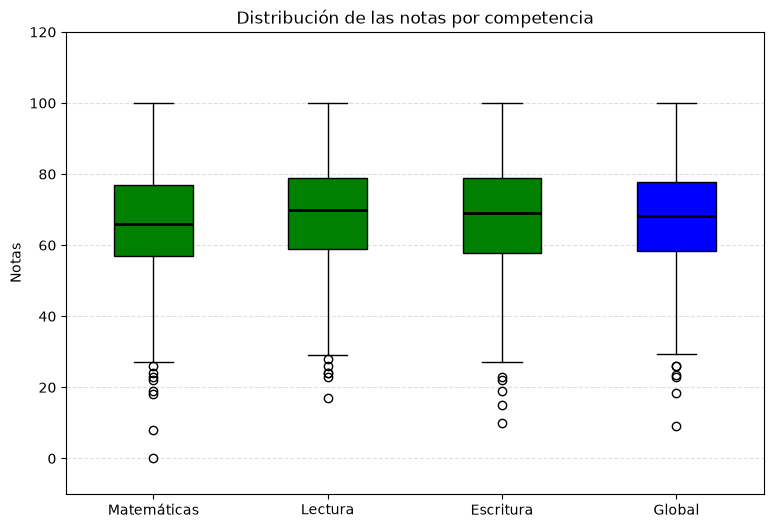

In [4]:
datos = [sp["math_score"], sp["reading_score"], sp["writing_score"], sp["global_score"]]

plt.figure(figsize=(9, 6))

box = plt.boxplot(datos, patch_artist=True, tick_labels=["Matemáticas", "Lectura", "Escritura", "Global"], orientation="vertical", medianprops={"color": "black", "linewidth": 2})

colores = ["green", "green", "green", "blue"]

for caja, color in zip(box["boxes"], colores):
    caja.set_facecolor(color)
    

plt.title("Distribución de las notas por competencia")
plt.ylabel("Notas")
plt.ylim(-10, 120)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.savefig("../img/Grafico_1_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

Ahora hacemos un gráfico de barras de cómo rinden los estudiantes en cada competencia:

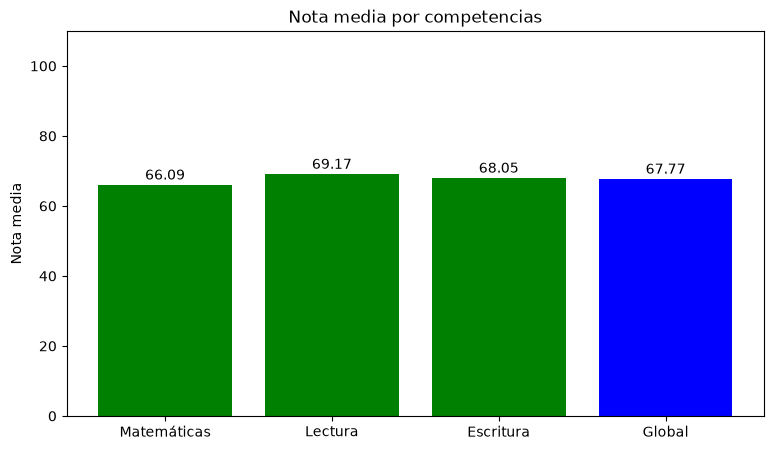

In [5]:
notas_medias = sp[["math_score", "reading_score", "writing_score", "global_score"]].mean()

colores = ["green", "green", "green", "blue"]

plt.figure(figsize=(9, 5))

notas_medias.index = ["Matemáticas", "Lectura", "Escritura", "Global"]

barras = plt.bar(notas_medias.index, notas_medias.values, color=colores)

for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width() / 2, altura + 0.5, f"{altura:.2f}", ha="center", va="bottom")

plt.title("Nota media por competencias")
plt.ylabel("Nota media")
plt.ylim(0, 110)

plt.savefig("../img/Grafico_1_2.jpg", dpi=300, bbox_inches="tight")

plt.show()

Con esto podría contestar preguntas como: 

- ¿En qué competencia obtienen mejores resultados?

    * Fijándonos en el gráfico de barras, la Lectura es la competencia con mejores resultados. Presenta los valores más altos en el primer y segundo cuartil (59 y 70), por lo que los resultados centrales son ligeramente mejores que el de las otras dos competencias.

- ¿Qué asignatura presenta mayor dispersión?

    * Fijándonos en el diagrama de cajas, Matemáticas es la competencia donde más dispersión se observa. Es, por tanto, la competencia que, quizás, más dificultad conlleva. Presenta los valores más bajos en los tres percentiles, lo que indica que, en general, los resultados son algo inferiores a los de las otras dos competencias.

- ¿Hay estudiantes con resultados especialmente bajos?

    * Para contestar a esta pregunta, nos fijamos en los diagramas de cajas, donde observamos que existen datos atípicos fuera del rango de los diagramas en las 3 competencias. Datos que identificamos como estudiantes con bajo rendimiento en todos los exámenes.
    Los percentiles indican la posición de su nota respecto a las notas del resto de estudiantes.

        Los percentiles indican la posición de su nota respecto a las notas del resto de estudiantes.

    Si fijamos en 50 -no incluido- (sobre 100) en las 3 competencias simultáneamente, la nota de corte para estudiar los datos de estudiantes que presentan bajo rendimiento, calculamos el porcentaje de alumnos que representan.


In [6]:
bajo_rendimiento = sp[(sp["math_score"] < 50) & (sp["reading_score"] < 50) & (sp["writing_score"] < 50)]

num_alumnos = len(bajo_rendimiento)
porcentaje = (num_alumnos / len(sp)) * 100

print("Alumnos con bajo rendimiento:", num_alumnos)
print(f"Porcentaje de alumnos: {porcentaje:.2f}%")

Alumnos con bajo rendimiento: 55
Porcentaje de alumnos: 5.50%


Existen 55 estudiantes con notas menores de 50 (sobre 100) en las 3 competencias simultáneamente. Con estos resultados, podría hacer foco para identificar patrones en los factores externos que representan al 5.50% de nuestra muestra.

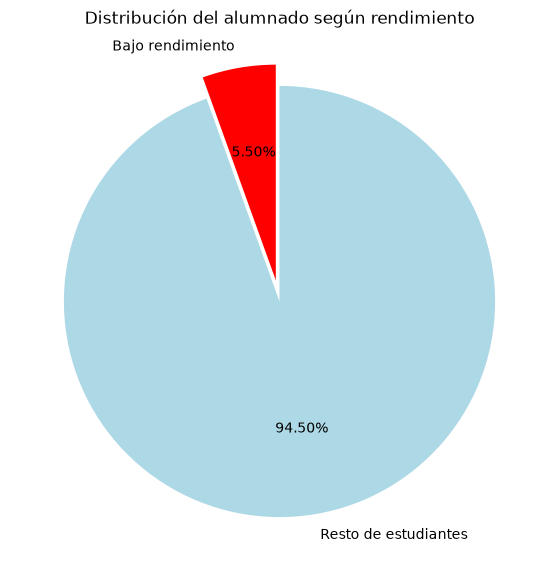

In [7]:
porcentaje_bajo = len(bajo_rendimiento) / len(sp) * 100
porcentaje_resto = 100 - porcentaje_bajo

etiquetas = ["Bajo rendimiento", "Resto de estudiantes"]
valores = [porcentaje_bajo, porcentaje_resto]

plt.figure(figsize=(7, 7))

plt.pie(valores, labels=etiquetas, autopct="%1.2f%%", startangle=90, explode=(0.1, 0), colors=["red", "lightblue"])

plt.title("Distribución del alumnado según rendimiento")

plt.savefig("../img/Grafico_1_3.jpg", dpi=300, bbox_inches="tight")

plt.show()

* Contexto del grupo de bajo rendimiento, siendo este que las 3 puntuaciones sean menores de 50 (sobre 100).

In [23]:
gender_bajorend = bajo_rendimiento["gender"].mode().unique()
race_bajorend = bajo_rendimiento["race_ethnicity"].mode().unique()
parental_bajorend = bajo_rendimiento["parental_level_of_education"].mode().unique()
lunch_bajorend = bajo_rendimiento["lunch"].mode().unique()
test_bajorend = bajo_rendimiento["test_preparation_course"].mode().unique()

print("Las características mayoritarias del grupo de bajo rendimiento son: ")
print("")
print("Gender: ", gender_bajorend.value_counts())
print("----------------------")
print("Race/Ethnicity: ", race_bajorend.value_counts())
print("----------------------")
print("Parental level of Education: ", parental_bajorend.value_counts())
print("----------------------")
print("School Lunch Program: ", lunch_bajorend.value_counts())
print("----------------------")
print("Test Preparation Course: ", test_bajorend.value_counts())

Las características mayoritarias del grupo de bajo rendimiento son: 

Gender:  male    1
Name: count, dtype: int64
----------------------
Race/Ethnicity:  group B    1
group C    1
Name: count, dtype: int64
----------------------
Parental level of Education:  high school    1
Name: count, dtype: int64
----------------------
School Lunch Program:  free/reduced    1
Name: count, dtype: int64
----------------------
Test Preparation Course:  not completed    1
Name: count, dtype: int64


Estos resultados nos llevan a investigar por esta línea aunque, por el momento, vamos a continuar con las hipótesis iniciales.

- ¿Qué porcentaje obtiene una puntuación superior a 70?

    * Ahora vamos a ver cuantos de estos estudiantes obtienen notas superiores a 70

In [9]:
alto_rendimiento = sp[(sp["math_score"] > 70) & (sp["reading_score"] > 70) & (sp["writing_score"] > 70)]

num_alumnos_alto = len(alto_rendimiento)
porcentaje = (num_alumnos_alto / len(sp)) * 100

print("Alumnos con alto rendimiento:", num_alumnos_alto)
print(f"Porcentaje de alumnos: {porcentaje:.2f}%")

Alumnos con alto rendimiento: 306
Porcentaje de alumnos: 30.60%


Existen 306 estudiantes con notas superiores a 70 (sobre 100) en las 3 competencias simultáneamente. Con estos resultados, podría hacer foco para identificar patrones en los factores externos que representan al 30.60% de nuestra muestra.

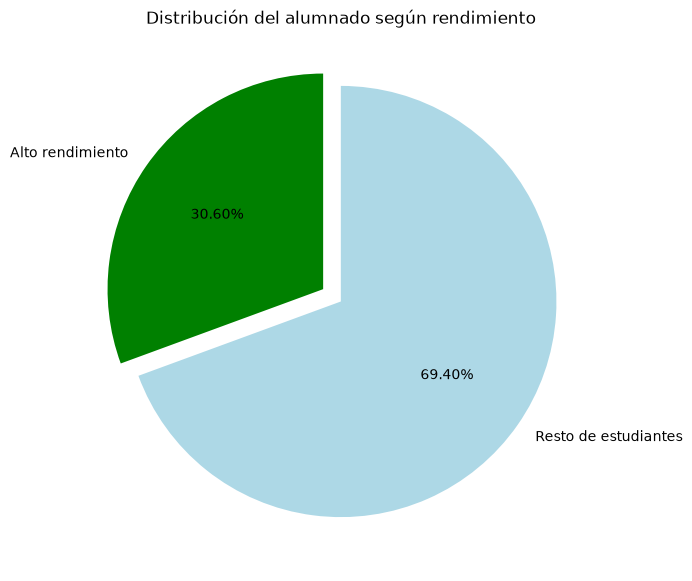

In [10]:
porcentaje_alto =( num_alumnos_alto / len(sp)) * 100
porcentaje_resto = 100 - porcentaje_alto

etiquetas = ["Alto rendimiento", "Resto de estudiantes"]
valores = [porcentaje_alto, porcentaje_resto]

plt.figure(figsize=(7, 7))

plt.pie(valores, labels=etiquetas, autopct="%1.2f%%", startangle=90, explode=(0.1, 0), colors=["green", "lightblue"])

plt.title("Distribución del alumnado según rendimiento")

plt.savefig("../img/Grafico_1_4.jpg", dpi=300, bbox_inches="tight")

plt.show()

Estos resultados tambien nos llevan a investigar por esta línea, incluso creando otra variable clasificatoria respecto a este rendimiento,  aunque vamos a continuar con las hipótesis iniciales.

* Contexto del grupo de alto rendimiento, siendo este que las 3 puntuaciones sean mayores de 70 (sobre 100).

In [19]:
gender_altorend = alto_rendimiento["gender"].mode().unique()
race_altorend = alto_rendimiento["race_ethnicity"].mode().unique()
parental_altorend = alto_rendimiento["parental_level_of_education"].mode().unique()
lunch_altorend = alto_rendimiento["lunch"].mode().unique()
test_altorend = alto_rendimiento["test_preparation_course"].mode().unique()

print("Las características mayoritarias del grupo de alto rendimiento son: ")
print("")
print("Gender: ", gender_altorend.value_counts())
print("----------------------")
print("Race/Ethnicity: ", race_altorend.value_counts())
print("----------------------")
print("Parental level of Education: ", parental_altorend.value_counts())
print("----------------------")
print("School Lunch Program: ", lunch_altorend.value_counts())
print("----------------------")
print("Test Preparation Course: ", test_altorend.value_counts())

Las características mayoritarias del grupo de alto rendimiento son: 

Gender:  female    1
Name: count, dtype: int64
----------------------
Race/Ethnicity:  group D    1
Name: count, dtype: int64
----------------------
Parental level of Education:  associate's degree    1
Name: count, dtype: int64
----------------------
School Lunch Program:  standard    1
Name: count, dtype: int64
----------------------
Test Preparation Course:  not completed    1
Name: count, dtype: int64
